# Fit.ly churn analysis

This notebook loads `data/fitly_churn_analysis.xlsx`, a seed-42 workbook with the study's customer counts and churn margins (400 customers, 114 churned). It runs EDA, segmentation, statistical tests, a shallow random forest, business metrics, and recommendations.

Charts are saved under `outputs/`. Matplotlib uses the non-interactive `Agg` backend, so Run All does not block on a plot window.

The held-out model score is printed from the test split. It is not assumed to be 92.5%.

In [1]:
import matplotlib
matplotlib.use("Agg")

import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
if not (ROOT / "fitly_churn_analysis.py").exists():
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import os
os.chdir(ROOT)

import pandas as pd

print("Repo root:", ROOT)

Repo root: /workspace


## Data

Customer Details is the source of truth. If the workbook is missing, `generate_data.py` builds it. Summary sheets are optional for the loader.

In [2]:
from IPython.display import Image, display

from generate_data import DEFAULT_WORKBOOK, generate_dataset
from fitly_churn_analysis import (
    ChurnPredictors,
    ChurnVisualizations,
    CustomerSegmentation,
    FitlyDataLoader,
    FitlyEDA,
    RecommendationEngine,
)

if not DEFAULT_WORKBOOK.exists():
    generate_dataset(DEFAULT_WORKBOOK)

loader = FitlyDataLoader(DEFAULT_WORKBOOK)
data = loader.load_data()
validated = loader.validate_data()
customers = data["Customer Details"]
print("validated:", validated)
print("sheets:", list(data))
display(customers.head(8))

Data validation passed (400 customers, fitly_churn_analysis.xlsx).
validated: True
sheets: ['Customer Details', 'Churn by Plan', 'Churn by Engagement', 'Data Validation', 'Summary Statistics', 'Support Analysis']


,Customer ID,Plan,Price,Churned,Support Tickets,Activities,Engagement,Avg Resolution Time
0,C10000,Free,0.0,1,3,1,High,19.71
1,C10001,Free,0.0,1,0,0,High,14.45
2,C10002,Free,0.0,1,4,0,High,19.29
3,C10003,Free,0.0,1,4,0,High,0.68
4,C10004,Free,0.0,1,1,0,High,9.53
5,C10005,Free,0.0,1,3,1,High,6.35
6,C10006,Free,0.0,1,1,0,High,12.07
7,C10007,Free,0.0,1,3,0,High,8.06


## Overall churn

114 of 400 customers churned (28.5%). 286 are still active. 41 active customers sit in Low or No Engagement; that is the at-risk pool.

In [3]:
import pandas as pd

eda = FitlyEDA(customers)
overall = eda.get_overall_metrics()
display(pd.DataFrame([overall]).T.rename(columns={0: "value"}))
print(
    f"Churn rate {overall['churn_rate']:.2%} "
    f"({overall['churned_customers']}/{overall['total_customers']}), "
    f"at-risk {overall['at_risk_customers']}"
)

,value
total_customers,400.000000
churned_customers,114.000000
active_customers,286.000000
churn_rate,0.285000
retention_rate,0.715000
active_mrr,13177.000000
churned_mrr,4408.480000
total_listed_mrr,17585.480000
avg_price_active,46.073427
avg_price_all,43.963700


Churn rate 28.50% (114/400), at-risk 41


## Churn by plan

Free 43/105 (41.0%), Basic 28/118 (23.7%), Pro 19/85 (22.4%), Enterprise 24/92 (26.1%). Free is the rate outlier. Paid plans sit between about 22% and 26%.

,Plan,Customers,Churned,Active,Churn Rate,Avg Price,Active MRR,Churned MRR
0,Free,105,43,62,0.409524,0.00,0.00,0.00
1,Basic,118,28,90,0.237288,19.87,1770.75,573.91
2,Pro,85,19,66,0.223529,53.74,3534.67,1033.23
3,Enterprise,92,24,68,0.260870,116.01,7871.58,2801.34


Saved /workspace/outputs/churn_by_plan.png


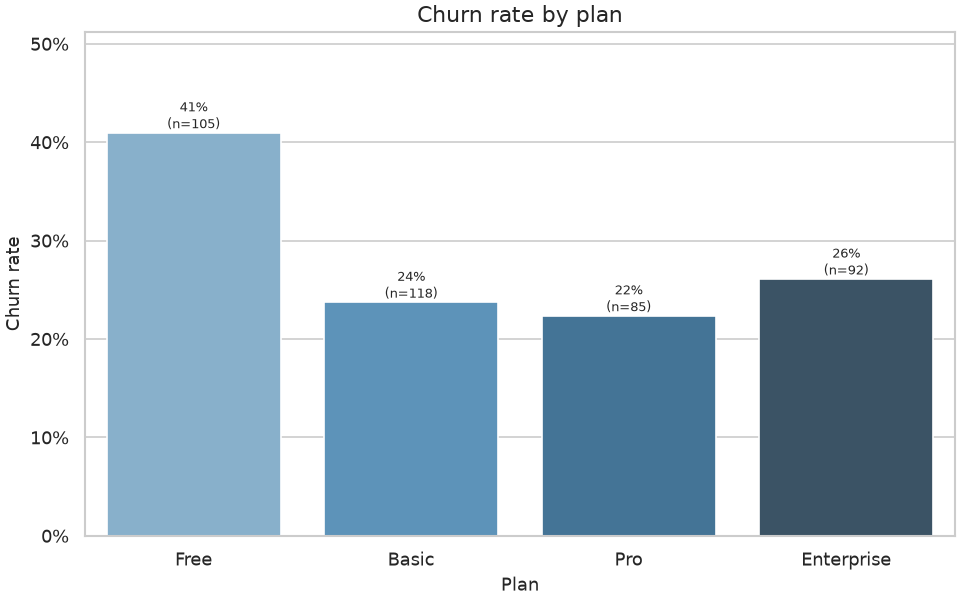

In [4]:
import pandas as pd

plan = eda.analyze_churn_by_plan()
display(plan)

charts = ChurnVisualizations(customers)
charts.set_style()
plan_chart = charts.plot_churn_by_plan()
display(Image(filename=str(plan_chart)))

## Churn by engagement

High 17/105 (16.2%), Medium 74/231 (32.0%), Low 20/56 (35.7%), No Engagement 3/8 (37.5%).

Medium holds most of the churned customers by count. Low and No Engagement have the highest rates. Their 41 still-active customers are the save list. Rates on plan × engagement cells with only one or two people (visible on the heatmap) are noisy.

,Engagement,Customers,Churned,Active,Churn Rate
0,High,105,17,88,0.161905
1,Medium,231,74,157,0.320346
2,Low,56,20,36,0.357143
3,No Engagement,8,3,5,0.375000


,Engagement,Customers,Share
0,High,105,0.2625
1,Medium,231,0.5775
2,Low,56,0.1400
3,No Engagement,8,0.0200


avg_tickets_active                    2.101399
avg_tickets_churned                   2.798246
avg_activities_active                 1.353147
avg_activities_churned                0.500000
avg_resolution_active                 9.979755
avg_resolution_churned               11.453947
ticket_gap_churned_minus_active       0.696847
activity_gap_churned_minus_active    -0.853147
Name: support, dtype: float64

Saved /workspace/outputs/churn_by_engagement.png


Saved /workspace/outputs/heatmap_plan_engagement.png


Saved /workspace/outputs/engagement_distribution.png


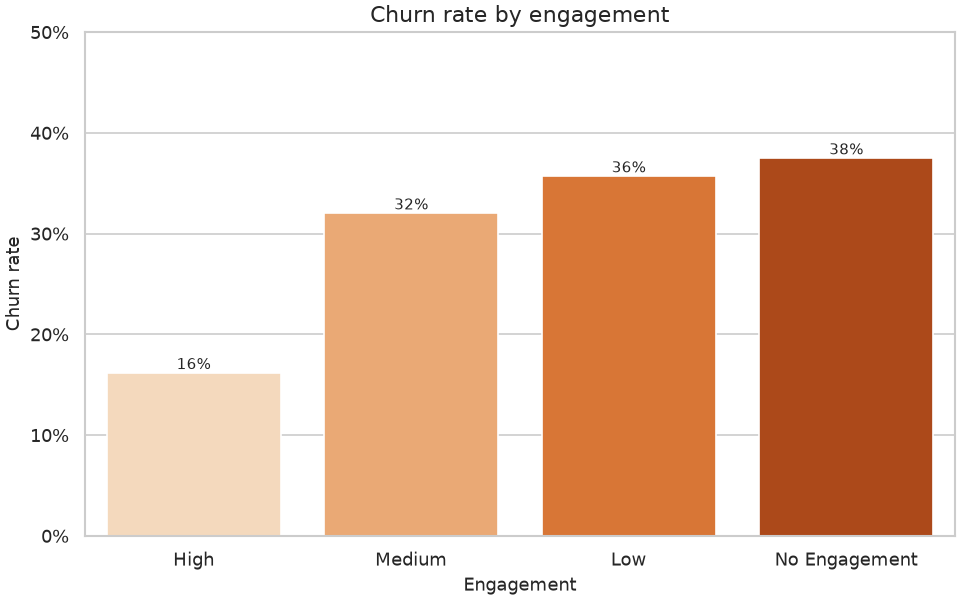

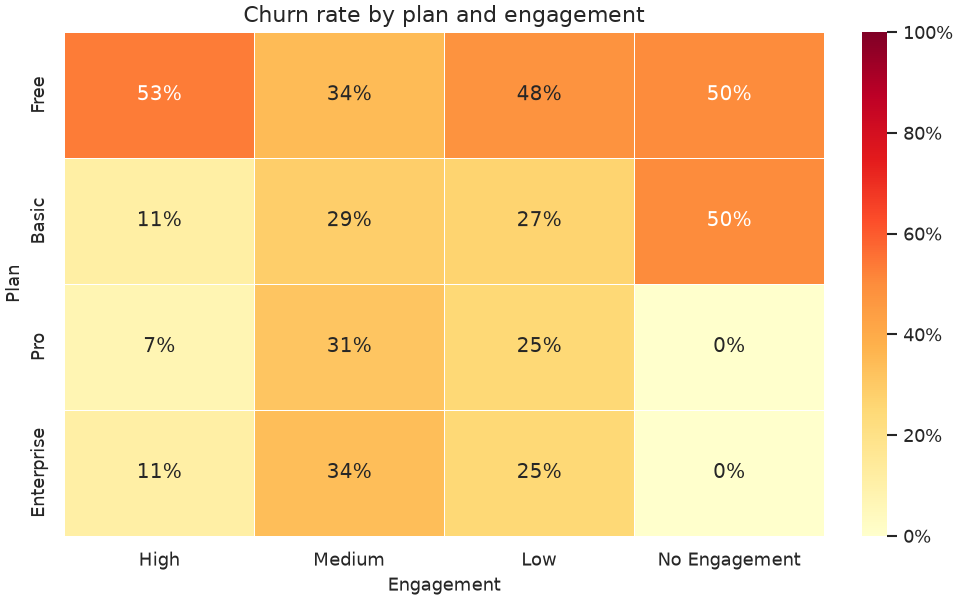

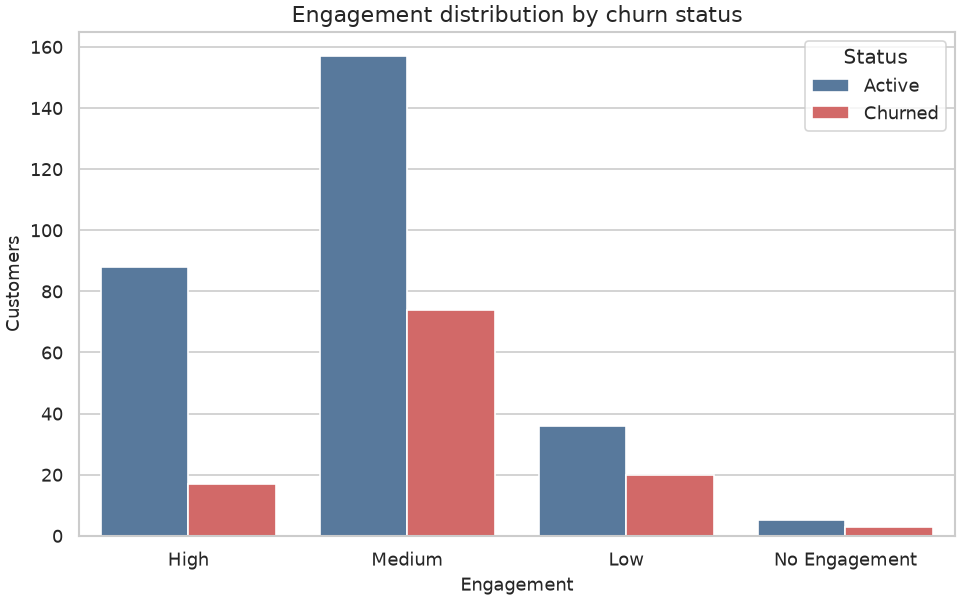

In [5]:
engagement = eda.analyze_churn_by_engagement()
distribution = eda.analyze_engagement_distribution()
support = eda.analyze_support_metrics()
display(engagement)
display(distribution)
display(pd.Series(support, name="support"))

engagement_chart = charts.plot_churn_by_engagement()
heatmap = charts.plot_heatmap_plan_engagement()
distribution_chart = charts.plot_engagement_distribution()
display(Image(filename=str(engagement_chart)))
display(Image(filename=str(heatmap)))
display(Image(filename=str(distribution_chart)))

## Predictors and segmentation

At-risk customers are active people in engagement levels whose historical churn rate is at least 35%. Retention potential uses the historical churn rate of the **paid** Low/No Engagement segment, including customers who already churned, and applies the gap to the still-active count only.

In [6]:
predictors = ChurnPredictors(customers)
display(predictors.analyze_plan_churn_impact())
display(predictors.analyze_engagement_churn_impact())
display(predictors.correlate_features().to_frame("correlation_with_churn"))
display(predictors.get_high_risk_segments(threshold=0.35))

segmentation = CustomerSegmentation(customers)
ltv = segmentation.segment_by_ltv()
ltv_summary = (
    ltv.groupby("LTV Segment", as_index=False)
    .agg(customers=("Customer ID", "count"), avg_ltv=("LTV", "mean"), churn_rate=("Churned", "mean"))
)
display(ltv_summary)

at_risk = segmentation.identify_at_risk(churn_threshold=0.35)
print("At-risk customers:", len(at_risk))
display(at_risk.head(8))
retention = segmentation.calculate_retention_potential()
display(pd.Series(retention, name="retention_potential"))

,Plan,Customers,Churned,Active,Churn Rate,Avg Price,Active MRR,Churned MRR,Overall Churn Rate,Rate Difference,Lift
0,Free,105,43,62,0.409524,0.00,0.00,0.00,0.285,0.124524,1.436926
1,Basic,118,28,90,0.237288,19.87,1770.75,573.91,0.285,-0.047712,0.832590
2,Pro,85,19,66,0.223529,53.74,3534.67,1033.23,0.285,-0.061471,0.784314
3,Enterprise,92,24,68,0.260870,116.01,7871.58,2801.34,0.285,-0.024130,0.915332


,Engagement,Customers,Churned,Active,Churn Rate,Overall Churn Rate,Rate Difference,Lift
0,High,105,17,88,0.161905,0.285,-0.123095,0.568087
1,Medium,231,74,157,0.320346,0.285,0.035346,1.124022
2,Low,56,20,36,0.357143,0.285,0.072143,1.253133
3,No Engagement,8,3,5,0.375000,0.285,0.090000,1.315789


,correlation_with_churn
Activities,-0.382663
Support Tickets,0.254312
Engagement (ordinal),-0.147787
Avg Resolution Time,0.121120
Plan (ordinal),-0.113697
Price,-0.076796


,Plan,Engagement,customers,churned,churn_rate,avg_price
0,Free,High,15,8,0.533333,0.00
1,Free,No Engagement,4,2,0.500000,0.00
2,Basic,No Engagement,2,1,0.500000,18.82
3,Free,Low,25,12,0.480000,0.00


,LTV Segment,customers,avg_ltv,churn_rate
0,Free,105,0.000,0.409524
1,High LTV,92,2227.392,0.260870
2,Low LTV,118,381.504,0.237288
3,Medium LTV,85,1031.808,0.223529


At-risk customers: 41


,Customer ID,Plan,Price,Churned,Support Tickets,Activities,Engagement,Avg Resolution Time,segment_churn_rate
0,C10088,Free,0.0,0,1,1,Low,9.80,0.357143
1,C10089,Free,0.0,0,2,4,Low,11.75,0.357143
2,C10090,Free,0.0,0,2,2,Low,13.66,0.357143
3,C10091,Free,0.0,0,1,2,Low,7.60,0.357143
4,C10092,Free,0.0,0,2,3,Low,14.16,0.357143
5,C10093,Free,0.0,0,2,2,Low,11.98,0.357143
6,C10094,Free,0.0,0,2,1,Low,2.62,0.357143
7,C10095,Free,0.0,0,2,1,Low,18.14,0.357143


segment                      Paid Low/No Engagement
segment_size                                     35
active_customers                                 26
churned_customers                                 9
current_churn_rate                         0.257143
target_churn_rate                               0.2
potential_customers_saved                  1.485714
avg_monthly_price                             54.78
potential_mrr_saved                           81.39
potential_ltv_saved                         1562.69
Name: retention_potential, dtype: object

## Statistical tests and the random forest

Plan and engagement are coded with a fixed order (Free=0 … Enterprise=3, No Engagement=0 … High=3), not `LabelEncoder`. The forest uses 100 trees, `max_depth=6`, and `min_samples_leaf=5`. The accuracy line below is the held-out score from this run.

In [7]:
from fitly_advanced_analysis import (
    BusinessMetrics,
    ChurnPredictionModel,
    CohortAnalysis,
    StatisticalAnalysis,
)

tests = StatisticalAnalysis(customers)
stats_results = {
    "plan_churn": tests.chi_square_plan_churn(),
    "engagement_churn": tests.chi_square_engagement_churn(),
    "support_tickets": tests.ttest_support_tickets_churn(),
    "activities": tests.ttest_activities_churn(),
}
stats_view = pd.DataFrame(
    [
        {
            "test": name,
            "statistic": result.get("statistic"),
            "p_value": result.get("p_value"),
            "significant_at_0_05": result.get("significant_at_0_05"),
        }
        for name, result in stats_results.items()
    ]
)
display(stats_view)

model = ChurnPredictionModel(customers)
model.prepare_data()
model.train_test_split_data()
model.train_random_forest()
importance = model.feature_importance_analysis()
predictions = model.predict_churn_risk()
display(importance)
display(predictions.head(10))
print(f"Test accuracy: {model.accuracy:.4f}")

,test,statistic,p_value,significant_at_0_05
0,plan_churn,11.147197,1.095598e-02,True
1,engagement_churn,10.972228,1.187700e-02,True
2,support_tickets,5.080812,8.770779e-07,True
3,activities,-10.478965,1.300388e-22,True


Class 0 (active): 286
Class 1 (churned): 114
Features: ['Plan', 'Price', 'Support Tickets', 'Activities', 'Engagement', 'Avg Resolution Time']
Train rows: 300 | Test rows: 100
Test class 0 (active): 71
Test class 1 (churned): 29
Majority-class baseline accuracy: 0.7100 (71.00%)
Test accuracy: 0.8500 (85.00%)
Test ROC AUC: 0.9097
Classification report:
              precision    recall  f1-score   support

           0      0.841     0.972     0.902        71
           1      0.889     0.552     0.681        29

    accuracy                          0.850       100
   macro avg      0.865     0.762     0.791       100
weighted avg      0.855     0.850     0.838       100

Feature importance:
            feature  importance
         Activities    0.310674
              Price    0.210443
Avg Resolution Time    0.201290
    Support Tickets    0.133298
         Engagement    0.077566
               Plan    0.066730


,feature,importance
0,Activities,0.310674
1,Price,0.210443
2,Avg Resolution Time,0.201290
3,Support Tickets,0.133298
4,Engagement,0.077566
5,Plan,0.066730


,Customer ID,churn_probability,predicted_churn,actual_churn
263,C10263,0.487488,0,1
222,C10222,0.420447,0,0
171,C10171,0.332012,0,0
90,C10090,0.113621,0,0
321,C10321,0.195466,0,0
199,C10199,0.381520,0,0
49,C10049,0.235950,0,0
239,C10239,0.061705,0,0
385,C10385,0.202386,0,0
293,C10293,0.158486,0,0


Test accuracy: 0.8500


## Cohorts and business metrics

Lifetime value uses 24 months and an 80% gross margin. CAC is $50. Payback is skipped for Free because the price is 0.

In [8]:
cohorts = CohortAnalysis(customers)
display(cohorts.analyze_plan_cohorts())
display(cohorts.analyze_engagement_cohorts())

business = BusinessMetrics(customers)
mrr = business.calculate_mrr_impact()
ltv_impact = business.calculate_ltv_impact()
payback = business.calculate_cac_payback()
display(pd.Series({key: value for key, value in mrr.items() if not isinstance(value, dict)}, name="mrr"))
display(pd.Series(ltv_impact, name="ltv"))
display(pd.Series(payback["payback_months_by_plan"], name="cac_payback_months"))

,Plan,customers,churned,active,churn_rate,avg_price,avg_support_tickets,avg_activities,avg_resolution_time,active_mrr,churned_mrr
0,Free,105,43,62,0.409524,0.00,2.333333,1.104762,10.908190,0.00,0.00
1,Basic,118,28,90,0.237288,19.87,2.398305,0.991525,10.684153,1770.75,573.91
2,Pro,85,19,66,0.223529,53.74,2.200000,1.294118,9.546235,3534.67,1033.23
3,Enterprise,92,24,68,0.260870,116.01,2.228261,1.097826,10.243913,7871.58,2801.34


,Engagement,customers,churned,active,churn_rate,avg_price,avg_support_tickets,avg_activities,avg_resolution_time,active_mrr,churned_mrr
0,High,105,17,88,0.161905,50.706571,2.038095,1.066667,10.120571,4785.25,538.94
1,Medium,231,74,157,0.320346,44.998052,2.333333,1.125541,10.525584,6967.42,3427.13
2,Low,56,20,36,0.357143,29.634821,2.571429,1.142857,10.106429,1236.28,423.27
3,No Engagement,8,3,5,0.375000,25.898750,2.875000,1.000000,12.491250,188.05,19.14


active_mrr       13177.00
churned_mrr       4408.48
mrr_lost          4408.48
potential_mrr    17585.48
Name: mrr, dtype: float64

lifetime_months         24.00
gross_margin             0.80
ltv_lost             84642.82
avg_ltv_churned        742.48
avg_ltv_active         884.61
total_active_ltv    252998.40
Name: ltv, dtype: float64

Free               NaN
Basic         3.145445
Pro           1.163007
Enterprise    0.538747
Name: cac_payback_months, dtype: float64

## Recommendations

Four actions are computed from the workbook: Free onboarding, re-engagement of the 41 at-risk accounts, a nurture for Medium engagement (the largest churn count), and an activation push because churned customers log fewer activities.

In [9]:
from fitly_utils import ReportGenerator

recommendations = RecommendationEngine(customers).generate_recommendations()
recommendation_table = pd.DataFrame(recommendations)
recommendation_table["actions"] = recommendation_table["actions"].apply(
    lambda actions: " | ".join(actions)
)
display(recommendation_table)

summary = ReportGenerator().generate_executive_summary(
    overall, plan, engagement, recommendations
)
print(summary)

assert validated is True
assert len(customers) == 400
assert int(customers["Churned"].sum()) == 114
assert len(at_risk) == 41
assert len(recommendations) == 4
for chart_path in (plan_chart, engagement_chart, heatmap, distribution_chart):
    assert chart_path.exists(), chart_path
print("Notebook checks passed.")

,priority,title,current_issue,actions,owner,timeline,expected_impact
0,P1,Fix Free-plan onboarding and the path to paid,"Free churn is 41.0% (43 of 105 customers), abo...",Review the first-week Free experience for drop...,Growth,30 days,Closing the gap with Basic on the 62 active Fr...
1,P2,Re-engage active low and no-engagement customers,Low engagement churns at 35.7% and No Engageme...,Open a save playbook for the 41 active Low and...,Customer Success,14 days,Moving the paid low/no-engagement churn rate f...
2,P3,Nurture the Medium engagement cohort,Medium engagement holds 74 of 114 churned cust...,Build a lifecycle track for Medium customers w...,Lifecycle Marketing,45 days,A nurture program on the active Medium group a...
3,P4,Increase product activity before accounts go q...,Churned customers average 0.50 activities vers...,Instrument an activation checklist and alert w...,Product,60 days,Raising product activity among quiet accounts ...


Fit.ly churn analysis — executive summary

Overall
total_customers: 400
churned_customers: 114
active_customers: 286
churn_rate: 0.285
retention_rate: 0.7150000000000001
active_mrr: 13177.0
churned_mrr: 4408.48
total_listed_mrr: 17585.48
avg_price_active: 46.073426573426566
avg_price_all: 43.963699999999996
avg_support_tickets: 2.3
avg_activities: 1.11
avg_resolution_time: 10.399900000000002
at_risk_customers: 41

Churn by plan
      Plan  Customers  Churned  Active  Churn Rate  Avg Price  Active MRR  Churned MRR
      Free        105       43      62    0.409524       0.00        0.00         0.00
     Basic        118       28      90    0.237288      19.87     1770.75       573.91
       Pro         85       19      66    0.223529      53.74     3534.67      1033.23
Enterprise         92       24      68    0.260870     116.01     7871.58      2801.34

Churn by engagement
   Engagement  Customers  Churned  Active  Churn Rate
         High        105       17      88    0.161905
    